# Анализ данных VK-LSVD

Годовой проект «Beyond Watch Time», Алексей Шашлов, 2026/27

Задача проекта — сравнить ранжирование по времени просмотра с ранжированием, которое учитывает явные реакции. Анализ охватывает качество данных, распределения признаков и их связь со временем просмотра и действиями пользователя.

| Обучающий период | Наблюдаемых пар | Пользователей | Клипов |
|:--|--:|--:|--:|
| Недели 0–24 | 35 612 447 | 100 000 | 165 821 |

Срез `up0.01_ir0.01` включает 100 тысяч наиболее активных пользователей и случайный 1% клипов. Основные расчёты используют все пары за недели 0–24; для pairplot выбраны 100 000 пар. Недели 25 и 26 оставлены для валидации и теста; ограничения разделения описаны в разделе 7.

Источники: [карточка VK-LSVD](https://huggingface.co/datasets/deepvk/VK-LSVD), [статья авторов, раздел 3.2](https://arxiv.org/html/2602.04567v1#S3.SS2).

## Единица наблюдения

Одна строка — уникальная пара «пользователь–клип» с параметрами первого взаимодействия. По описанию авторов датасета, timespent суммируется по просмотрам пары и ограничен 255 секундами. Поэтому время может превышать длину клипа даже при отсутствии повторных строк.

Отношение timespent / duration показывает накопленное время относительно длины клипа. Значение 1 могло получиться за несколько частичных просмотров, поэтому называть его фактическим досмотром нельзя. Момент каждой реакции и границы накопления повторных просмотров в схеме не указаны.

| Поля | Что описывают |
|---|---|
| user_id, item_id, author_id | Пользователя, клип и автора; числовой порядок ID не имеет смысла |
| duration, age | Длительность клипа и возраст пользователя |
| gender, geo, place, platform, agent | Категории пользователя и контекста; расшифровки кодов контекста и географии нет |
| timespent | Накопленное время просмотра пары |
| like, dislike, share, bookmark, click_on_author, open_comments | Флаги наблюдаемых реакций |
| train_interactions_rank | Ранг активности, использованный при отборе данных |
| Неделя | Неделю первого взаимодействия пары |

Отсутствующая пара не означает отрицательную реакцию. Здесь есть отклики только на клипы, выбранные существующей рекомендательной системой.

Инструкция по запуску и подготовке данных — в [README](../README.md#анализ-данных).

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"

# Обучающие недели 0–24
train_files = []
for week in range(25):
    path = RAW / f"subsamples/up0.01_ir0.01/train/week_{week:02d}.parquet"
    assert path.exists(), f"Не найден файл {path}"
    train_files.append(str(path))

con = duckdb.connect(config={"threads": 4, "memory_limit": "4GB"})
con.read_parquet(train_files, filename=True).create_view("shows")
con.read_parquet(str(RAW / "metadata/items_metadata.parquet")).create_view("items_raw")
con.read_parquet(str(RAW / "metadata/users_metadata.parquet")).create_view("users_raw");

In [2]:
# Оформление графиков и таблиц
BLUE, ORANGE, GRAY = "#2166ac", "#cb5b35", "#8493a5"
INK, MUTED = "#19334c", "#64748b"
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.labelcolor": INK, "text.color": INK,
    "grid.color": "#e7edf3", "axes.grid.axis": "y",
    "legend.frameon": False, "legend.fontsize": 10,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.options.display.float_format = "{:,.3f}".format

REACTIONS = ["like", "dislike", "share", "bookmark", "click_on_author", "open_comments"]
LABELS = {
    "like": "Лайк", "dislike": "Дизлайк", "share": "Поделиться",
    "bookmark": "Закладка", "click_on_author": "К автору", "open_comments": "Комментарии"
}
COLORS = {
    "like": BLUE, "dislike": ORANGE, "share": "#168581",
    "bookmark": "#8262aa", "click_on_author": "#9a712e", "open_comments": "#526c84"
}

## 1. Качество данных

Проверяем уникальность пар и ключей, пропуски и покрытие метаданными. Метаданные ограничены пользователями и клипами обучающего периода.

In [3]:
con.execute("""
    CREATE TEMP TABLE items AS
    SELECT * FROM items_raw
    SEMI JOIN (SELECT DISTINCT item_id FROM shows) USING(item_id)
""")
con.execute("""
    CREATE TEMP TABLE users AS
    SELECT * FROM users_raw
    SEMI JOIN (SELECT DISTINCT user_id FROM shows) USING(user_id)
""");

In [4]:
passport = con.sql("""
    SELECT count(*) AS rows_cnt, count(DISTINCT user_id) AS users_cnt,
           count(DISTINCT item_id) AS items_cnt, count(DISTINCT filename) AS weeks_cnt,
           min(parse_filename(filename, true)) AS first_week,
           max(parse_filename(filename, true)) AS last_week
    FROM shows
""").df()
N = int(passport.loc[0, "rows_cnt"])
assert N == 35_612_447 and int(passport.loc[0, "weeks_cnt"]) == 25

In [5]:
table = passport.copy()
table.columns = ["Пар", "Пользователей", "Клипов", "Недель", "Первый файл", "Последний файл"]
display(table)

,Пар,Пользователей,Клипов,Недель,Первый файл,Последний файл
0,35612447,100000,165821,25,week_00,week_24


### Уникальность и полнота

В таблице приведено число нарушений для каждой проверки.

In [6]:
quality = con.sql("""
    WITH duplicate_pairs AS (
        SELECT user_id, item_id FROM shows
        GROUP BY user_id, item_id HAVING count(*) > 1
    )
    SELECT 'duplicate_pairs' AS check_name, count(*) AS n FROM duplicate_pairs
    UNION ALL
    SELECT 'duplicate_item_keys', count(*) - count(DISTINCT item_id) FROM items
    UNION ALL
    SELECT 'duplicate_user_keys', count(*) - count(DISTINCT user_id) FROM users
    UNION ALL
    SELECT 'rows_without_item', count(*) FROM shows ANTI JOIN items USING(item_id)
    UNION ALL
    SELECT 'rows_without_user', count(*) FROM shows ANTI JOIN users USING(user_id)
    UNION ALL
    SELECT 'rows_with_null', count(*) FROM shows
    WHERE user_id IS NULL OR item_id IS NULL OR timespent IS NULL
       OR place IS NULL OR platform IS NULL OR agent IS NULL OR "like" IS NULL
       OR dislike IS NULL OR share IS NULL OR bookmark IS NULL
       OR click_on_author IS NULL OR open_comments IS NULL
    UNION ALL
    SELECT 'items_with_null', count(*) FROM items
    WHERE item_id IS NULL OR author_id IS NULL OR duration IS NULL OR train_interactions_rank IS NULL
    UNION ALL
    SELECT 'users_with_null', count(*) FROM users
    WHERE user_id IS NULL OR age IS NULL OR gender IS NULL OR geo IS NULL OR train_interactions_rank IS NULL
""").df()
quality = quality.set_index("check_name")
quality.columns = ["Количество"]
assert quality["Количество"].eq(0).all()

In [7]:
table = quality.copy()
table.index = [
    "Повторные пары пользователь–клип", "Повторные ключи клипов", "Повторные ключи пользователей",
    "Пары без метаданных клипа", "Пары без метаданных пользователя",
    "Строки взаимодействий с NULL", "Клипы с NULL", "Пользователи с NULL"
]
display(table)

column_summary = []
for table_name in ["shows", "items", "users"]:
    part = con.sql(f"SUMMARIZE {table_name}").df()
    part = part.loc[part["column_name"] != "filename"]
    part = part[["column_name", "column_type", "count", "null_percentage"]]
    part.insert(0, "table", table_name)
    column_summary.append(part)
column_summary = pd.concat(column_summary, ignore_index=True)
column_summary.columns = ["Таблица", "Поле", "Тип", "Строк", "NULL, %"]
display(column_summary)

,Количество
Повторные пары пользователь–клип,0
Повторные ключи клипов,0
Повторные ключи пользователей,0
Пары без метаданных клипа,0
Пары без метаданных пользователя,0
Строки взаимодействий с NULL,0
Клипы с NULL,0
Пользователи с NULL,0


,Таблица,Поле,Тип,Строк,"NULL, %"
0,shows,user_id,UINTEGER,35612447,0.000
1,shows,item_id,UINTEGER,35612447,0.000
2,shows,place,UTINYINT,35612447,0.000
3,shows,platform,UTINYINT,35612447,0.000
4,shows,agent,UTINYINT,35612447,0.000
5,shows,timespent,UTINYINT,35612447,0.000
6,shows,like,BOOLEAN,35612447,0.000
7,shows,dislike,BOOLEAN,35612447,0.000
8,shows,share,BOOLEAN,35612447,0.000
9,shows,bookmark,BOOLEAN,35612447,0.000


### Числовые и категориальные признаки

Время считаем по парам, длительность — по уникальным клипам, возраст — по пользователям.

In [8]:
numeric_stats = con.sql("""
    SELECT 'Время, с' AS feature, 'строки взаимодействий' AS unit,
           count(*) AS n, min(timespent) AS min_value, avg(timespent) AS mean_value,
           stddev_pop(timespent) AS std_value,
           quantile_cont(timespent, 0.25) AS p25, median(timespent) AS p50,
           quantile_cont(timespent, 0.75) AS p75, quantile_cont(timespent, 0.99) AS p99,
           max(timespent) AS max_value
    FROM shows
    UNION ALL
    SELECT 'Длительность, с', 'уникальные клипы', count(*), min(duration), avg(duration),
           stddev_pop(duration), quantile_cont(duration, 0.25), median(duration),
           quantile_cont(duration, 0.75), quantile_cont(duration, 0.99), max(duration)
    FROM items
    UNION ALL
    SELECT 'Возраст, лет', 'уникальные пользователи', count(*), min(age), avg(age),
           stddev_pop(age), quantile_cont(age, 0.25), median(age),
           quantile_cont(age, 0.75), quantile_cont(age, 0.99), max(age)
    FROM users
""").df()

In [9]:
table = numeric_stats.drop(columns="unit")
table.columns = ["Поле", "Объём", "Мин.", "Среднее", "Ст. откл.", "Q25", "Медиана", "Q75", "Q99", "Макс."]
display(table)

,Поле,Объём,Мин.,Среднее,Ст. откл.,Q25,Медиана,Q75,Q99,Макс.
0,"Время, с",35612447,1,17.333,24.304,2.000,7.000,22.000,109.000,255
1,"Длительность, с",165821,5,34.652,30.098,12.000,25.000,52.000,159.000,180
2,"Возраст, лет",100000,18,34.478,10.863,26.000,33.000,41.000,65.000,70


In [10]:
categories = con.sql("""
    SELECT 'place' AS feature, count(DISTINCT place) AS categories_cnt, min(place) AS min_code, max(place) AS max_code FROM shows
    UNION ALL SELECT 'platform', count(DISTINCT platform), min(platform), max(platform) FROM shows
    UNION ALL SELECT 'agent', count(DISTINCT agent), min(agent), max(agent) FROM shows
    UNION ALL SELECT 'gender', count(DISTINCT gender), min(gender), max(gender) FROM users
    UNION ALL SELECT 'geo', count(DISTINCT geo), min(geo), max(geo) FROM users
""").df()

In [11]:
table = categories.copy()
table.columns = ["Поле", "Категорий", "Мин. код", "Макс. код"]
display(table)

user_ranks = con.sql("""
    SELECT min(train_interactions_rank) AS min_rank,
           max(train_interactions_rank) AS max_rank,
           count(DISTINCT train_interactions_rank) AS unique_ranks
    FROM users
""").df()
user_ranks.columns = ["Минимальный ранг", "Максимальный ранг", "Различных рангов"]
display(user_ranks)

# Проверяем допустимость значений до деления времени на длительность.
assert numeric_stats.loc[0, "min_value"] >= 0
assert numeric_stats.loc[0, "max_value"] <= 255
assert numeric_stats.loc[1, "min_value"] > 0
assert numeric_stats.loc[2, "min_value"] >= 18
assert numeric_stats.loc[2, "max_value"] <= 70

,Поле,Категорий,Мин. код,Макс. код
0,place,24,0,23
1,platform,11,0,10
2,agent,26,0,28
3,gender,2,1,2
4,geo,80,0,79


,Минимальный ранг,Максимальный ранг,Различных рангов
0,0,99999,100000


Повторных пар и ключей нет. Все взаимодействия имеют метаданные; NULL не найдены ни в одном исходном поле. Заполнение пропусков и удаление дублей не нужны.

Длительности лежат в диапазоне 5–180 с, точная медиана — 25 с. Возраст — 18–70 лет, медиана — 33 года. Ранги пользователей идут от 0 до 99 999: это срез наиболее активной аудитории.

В срезе 26 значений agent; глобальная карточка датасета описывает 29. Нулевые коды сохраняются как категории, поскольку их смысл не документирован. По одним крайним значениям возраста нельзя установить, применяли ли авторы фильтрацию или отсечение.

### Таблица для анализа

К парам добавляем метаданные и группы длительности, относительного времени и возраста.

In [12]:
con.execute("""
    CREATE TEMP TABLE facts AS
    SELECT s.user_id, s.item_id, i.author_id, s.timespent, i.duration,
           s.timespent::DOUBLE / i.duration AS watch_ratio,
           s."like", s.dislike, s.share, s.bookmark, s.click_on_author, s.open_comments,
           u.age, u.gender, u.geo, s.place, s.platform, s.agent,
           right(parse_filename(s.filename, true), 2)::INTEGER AS week,
           CASE WHEN i.duration <= 15 THEN '5–15'
                WHEN i.duration <= 30 THEN '16–30'
                WHEN i.duration <= 60 THEN '31–60'
                WHEN i.duration <= 90 THEN '61–90' ELSE '91–180' END AS duration_bin,
           CASE WHEN s.timespent::DOUBLE / i.duration < 0.25 THEN '<0,25'
                WHEN s.timespent::DOUBLE / i.duration < 0.50 THEN '[0,25; 0,5)'
                WHEN s.timespent::DOUBLE / i.duration < 0.75 THEN '[0,5; 0,75)'
                WHEN s.timespent < i.duration THEN '[0,75; 1)'
                WHEN s.timespent < 2 * i.duration::INTEGER THEN '[1; 2)'
                ELSE '≥2' END AS ratio_bin,
           CASE WHEN u.age < 25 THEN '18–24' WHEN u.age < 35 THEN '25–34'
                WHEN u.age < 45 THEN '35–44' WHEN u.age < 55 THEN '45–54'
                ELSE '55–70' END AS age_bin
    FROM shows s JOIN items i USING(item_id) JOIN users u USING(user_id)
""")
assert con.sql("SELECT count(*) FROM facts").fetchall()[0][0] == N
DURATION_ORDER = ["5–15", "16–30", "31–60", "61–90", "91–180"]
RATIO_ORDER = ["<0,25", "[0,25; 0,5)", "[0,5; 0,75)", "[0,75; 1)", "[1; 2)", "≥2"]

## 2. Время просмотра и длительность клипа

Время считаем по парам, длительность — по уникальным клипам. В таблице взаимодействий популярный клип встречается много раз, поэтому эти способы взвешивания дают разные распределения.

In [13]:
time_dist = con.sql("SELECT timespent, count(*) AS n FROM facts GROUP BY timespent ORDER BY timespent").df()
duration_dist = con.sql("SELECT duration, count(*) AS n FROM items GROUP BY duration ORDER BY duration").df()
time_thresholds = con.sql("""
    SELECT 'Время = 1 с' AS condition, count(*) FILTER (WHERE timespent = 1) AS n FROM facts
    UNION ALL SELECT 'Время ≤ 3 с', count(*) FILTER (WHERE timespent <= 3) FROM facts
    UNION ALL SELECT 'Время ≤ 5 с', count(*) FILTER (WHERE timespent <= 5) FROM facts
    UNION ALL SELECT 'Время = 255 с', count(*) FILTER (WHERE timespent = 255) FROM facts
    UNION ALL SELECT 'Время ≥ длительности', count(*) FILTER (WHERE timespent >= duration) FROM facts
    UNION ALL SELECT 'Время > длительности', count(*) FILTER (WHERE timespent > duration) FROM facts
    UNION ALL SELECT 'Время ≥ 2 длительностей', count(*) FILTER (WHERE timespent >= 2 * duration::INTEGER) FROM facts
""").df()
time_thresholds["pct"] = 100 * time_thresholds["n"] / N

In [14]:
table = time_thresholds.copy()
table.columns = ["Условие", "Пар", "Доля, %"]
display(table)

,Условие,Пар,"Доля, %"
0,Время = 1 с,5394358,15.147
1,Время ≤ 3 с,11830458,33.220
2,Время ≤ 5 с,15680045,44.030
3,Время = 255 с,17548,0.049
4,Время ≥ длительности,8684336,24.386
5,Время > длительности,5380784,15.109
6,Время ≥ 2 длительностей,766361,2.152


In [15]:
short_clips = con.sql("""
    SELECT 'Уникальные клипы' AS unit, count(*) AS total,
           count(*) FILTER (WHERE duration <= 15) AS short_cnt,
           100.0 * avg((duration <= 15)::INTEGER) AS short_pct FROM items
    UNION ALL
    SELECT 'Строки взаимодействий', count(*), count(*) FILTER (WHERE duration <= 15),
           100.0 * avg((duration <= 15)::INTEGER) FROM facts
""").df()

In [16]:
table = short_clips.copy()
table.columns = ["Единица", "Всего", "Длительность ≤15 с", "Доля, %"]
display(table)

,Единица,Всего,Длительность ≤15 с,"Доля, %"
0,Уникальные клипы,165821,57123,34.449
1,Строки взаимодействий,35612447,9601943,26.962


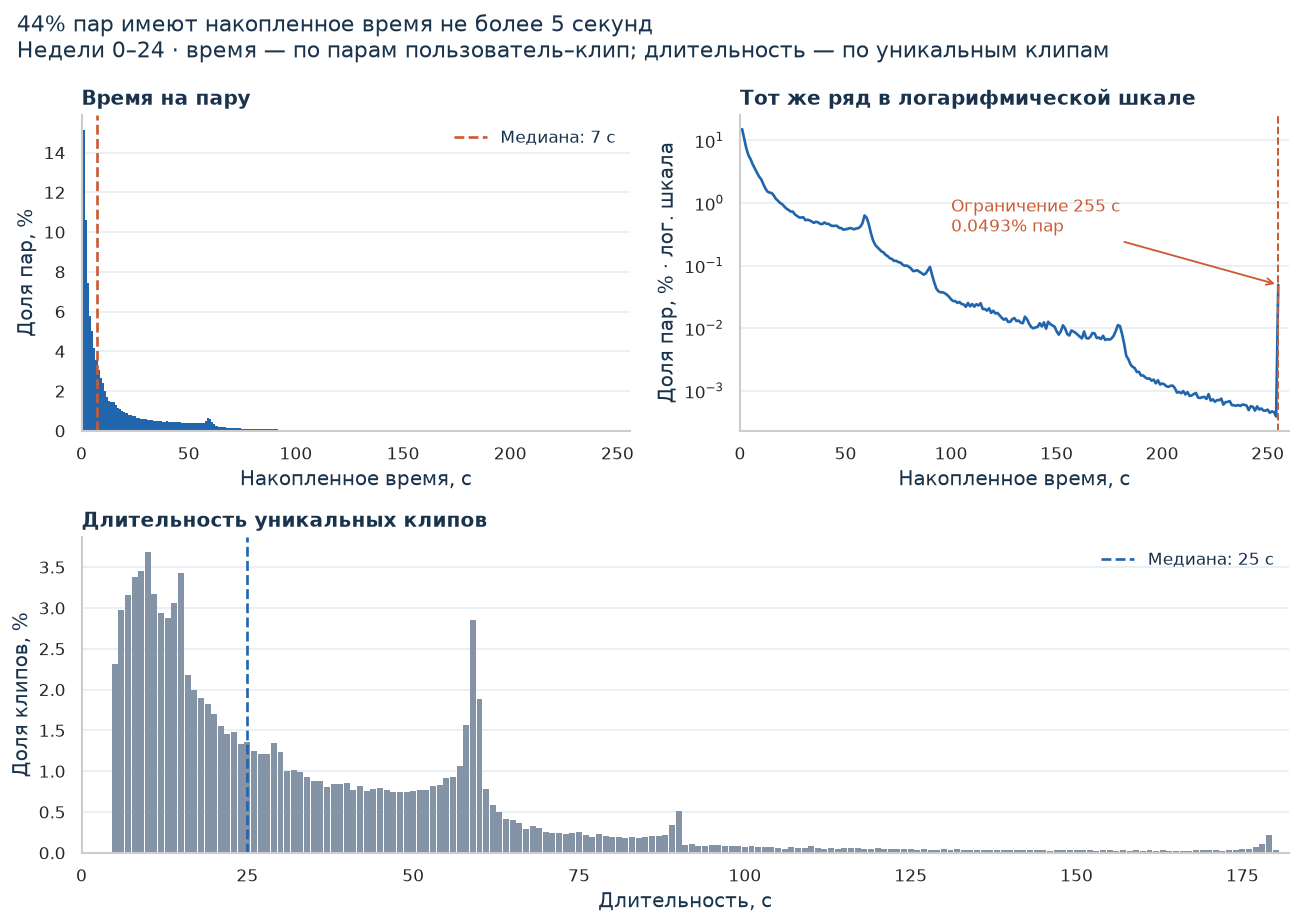

In [17]:
fig = plt.figure(figsize=(11, 8))
grid = fig.add_gridspec(2, 2)
ax_time = fig.add_subplot(grid[0, 0])
ax_tail = fig.add_subplot(grid[0, 1])
ax_duration = fig.add_subplot(grid[1, :])
time_pct = 100 * time_dist["n"] / N
duration_pct = 100 * duration_dist["n"] / duration_dist["n"].sum()

ax_time.bar(time_dist["timespent"], time_pct, width=1, color=BLUE, linewidth=0)
ax_time.axvline(7, color=ORANGE, ls="--", lw=1.6, label="Медиана: 7 с")
ax_time.set(title="Время на пару", xlabel="Накопленное время, с", ylabel="Доля пар, %", xlim=(0, 256))
ax_time.legend(loc="upper right")

ax_tail.plot(time_dist["timespent"], time_pct, color=BLUE, lw=1.6)
ax_tail.set(title="Тот же ряд в логарифмической шкале",
            xlabel="Накопленное время, с", ylabel="Доля пар, % · лог. шкала",
            yscale="log", xlim=(0, 260))
cap_pct = float(time_thresholds.loc[time_thresholds["condition"] == "Время = 255 с", "pct"].iloc[0])
ax_tail.axvline(255, color=ORANGE, ls="--", lw=1.2)
ax_tail.annotate(f"Ограничение 255 с\n{cap_pct:.4f}% пар",
                 xy=(255, cap_pct), xytext=(100, 0.35), fontsize=10, color=ORANGE,
                 arrowprops={"arrowstyle": "->", "color": ORANGE, "lw": 1.1})

ax_duration.bar(duration_dist["duration"], duration_pct, width=0.9, color=GRAY, linewidth=0)
ax_duration.axvline(25, color=BLUE, ls="--", lw=1.6, label="Медиана: 25 с")
ax_duration.set(title="Длительность уникальных клипов", xlabel="Длительность, с",
                ylabel="Доля клипов, %", xlim=(0, 182))
ax_duration.legend(loc="upper right")
fig.suptitle('44% пар имеют накопленное время не более 5 секунд\nНедели 0–24 · время — по парам пользователь–клип; длительность — по уникальным клипам', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

У 44,03% пар время не превышает 5 с. Медиана — 7 с, среднее — 17,33 с: его повышает длинный правый хвост. Клипы до 15 с составляют 34,45% уникальных клипов и 26,96% строк взаимодействий.

У 24,39% пар время достигает длительности клипа, у 15,11% превышает её, у 2,15% достигает двух длительностей. Эти условия относятся к накопленному времени; число полных просмотров по ним определить нельзя.

На границе 255 с находятся 17 548 пар — 0,0493%. Насколько ограничение уменьшило среднее время, по выгрузке неизвестно. Для клипов от 128 с отношение времени к длительности вообще не может достигнуть 2.

## 3. Реакции и их сочетания

Частота действия — число пар с соответствующим флагом на 1000 наблюдаемых пар. Повторные нажатия отдельно не считаются. В одной паре могут встречаться несколько разных действий.

In [18]:
reaction_summary = []
for reaction in REACTIONS:
    row = con.sql("""
        SELECT count(*) AS n, sum("{reaction}"::INTEGER) AS reaction_cnt,
               count(DISTINCT user_id) FILTER (WHERE "{reaction}") AS users_with_reaction
        FROM facts
    """.format(reaction=reaction)).df()
    row.insert(0, "reaction", reaction)
    reaction_summary.append(row)
reaction_summary = pd.concat(reaction_summary, ignore_index=True).set_index("reaction")
reaction_summary["per_1000"] = 1000 * reaction_summary["reaction_cnt"] / reaction_summary["n"]

In [19]:
table = reaction_summary[["reaction_cnt", "per_1000", "users_with_reaction"]].copy()
table["reaction_cnt"] = table["reaction_cnt"].astype("int64")
table.index = table.index.map(LABELS)
table.columns = ["Пар с действием", "На 1000 пар", "Пользователей с действием"]
display(table)

no_reaction_table = con.sql("""
    SELECT count(*) AS n FROM facts
    WHERE NOT ("like" OR dislike OR share OR bookmark OR click_on_author OR open_comments)
""").df()
no_reaction = int(no_reaction_table.loc[0, "n"])
no_reaction_pct = 100 * no_reaction / N
print(f"Без любой из шести реакций: {no_reaction:,} пар ({no_reaction_pct:.2f}%).")

,Пар с действием,На 1000 пар,Пользователей с действием
reaction,,,
Лайк,762927,21.423,49646
Дизлайк,9384,0.264,5465
Поделиться,157033,4.409,36854
Закладка,31503,0.885,9427
К автору,74514,2.092,30425
Комментарии,531035,14.911,52089


Без любой из шести реакций: 34,157,765 пар (95.92%).


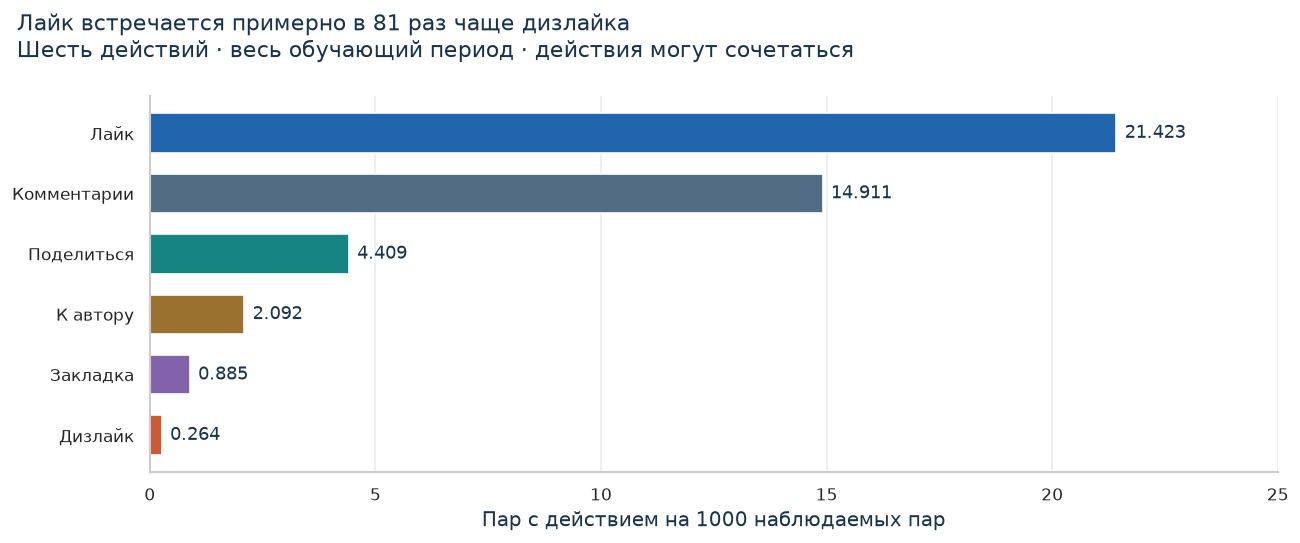

In [20]:
plot_rates = reaction_summary["per_1000"].sort_values()
fig, ax = plt.subplots(figsize=(11, 4.7))
bars = ax.barh(plot_rates.index.map(LABELS), plot_rates,
               color=plot_rates.index.map(COLORS), height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=11)
ax.set(xlabel="Пар с действием на 1000 наблюдаемых пар", xlim=(0, 25))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.suptitle('Лайк встречается примерно в 81 раз чаще дизлайка\nШесть действий · весь обучающий период · действия могут сочетаться', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

Лайк есть у 21,423 пары на 1000, дизлайк — у 0,264. У 95,92% пар нет ни одной из шести реакций. Это не означает недовольства: человек мог смотреть клип без дополнительных действий.

Хотя бы один лайк есть у 49 646 пользователей из 100 000, дизлайк — у 5 465. Всего дизлайков 9 384, поэтому в небольших группах нужно смотреть и на частоту, и на число событий.

In [21]:
cooccurrence = []
for reaction in REACTIONS:
    row = con.sql("""
        SELECT sum(("{reaction}" AND "like")::INTEGER) AS "like",
               sum(("{reaction}" AND dislike)::INTEGER) AS dislike,
               sum(("{reaction}" AND share)::INTEGER) AS share,
               sum(("{reaction}" AND bookmark)::INTEGER) AS bookmark,
               sum(("{reaction}" AND click_on_author)::INTEGER) AS click_on_author,
               sum(("{reaction}" AND open_comments)::INTEGER) AS open_comments
        FROM facts
    """.format(reaction=reaction)).df()
    row.index = [reaction]
    cooccurrence.append(row)
cooccurrence = pd.concat(cooccurrence).astype("int64")

In [22]:
table = cooccurrence.rename(index=LABELS, columns=LABELS)
display(table)

# Для каждой строки знаменатель — число пар с указанной реакцией.
conditional_pct = cooccurrence.div(reaction_summary["reaction_cnt"], axis=0) * 100
# На диагонали всегда 100%; скрываем её, чтобы выделить сочетания разных действий.
conditional_pct = conditional_pct.mask(np.eye(6, dtype=bool))

,Лайк,Дизлайк,Поделиться,Закладка,К автору,Комментарии
Лайк,762927,306,22319,14307,4187,47855
Дизлайк,306,9384,60,129,92,583
Поделиться,22319,60,157033,2496,2242,13941
Закладка,14307,129,2496,31503,513,3760
К автору,4187,92,2242,513,74514,6879
Комментарии,47855,583,13941,3760,6879,531035


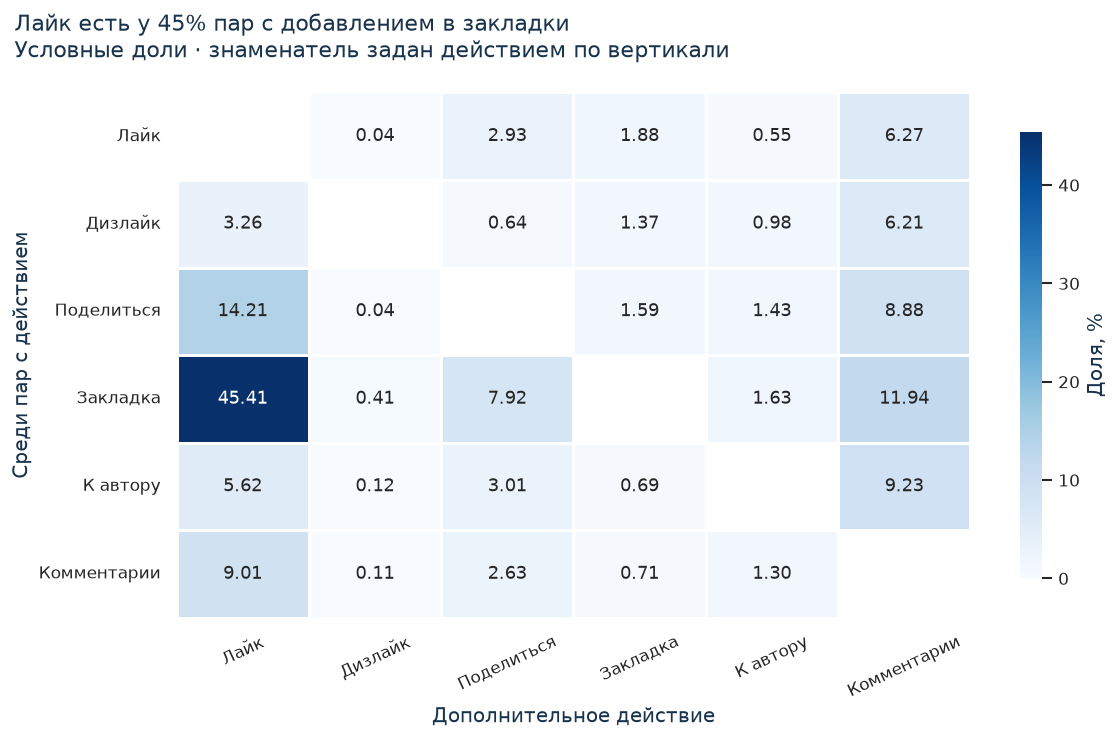

In [23]:
fig, ax = plt.subplots(figsize=(10, 6.4))
table = conditional_pct.rename(index=LABELS, columns=LABELS)
sns.heatmap(table, annot=True, fmt=".2f", annot_kws={"size": 11},
            cmap="Blues", vmin=0, linewidths=0.7, ax=ax,
            cbar_kws={"label": "Доля, %", "shrink": 0.85})
ax.set(xlabel="Дополнительное действие", ylabel="Среди пар с действием")
ax.grid(False)
ax.tick_params(axis="x", rotation=25)
ax.tick_params(axis="y", rotation=0)
fig.suptitle('Лайк есть у 45% пар с добавлением в закладки\nУсловные доли · знаменатель задан действием по вертикали', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

Среди пар с закладкой лайк есть у 45,41%; среди пар с лайком закладка есть у 1,88%. Знаменатели разные, поэтому условные доли в матрице несимметричны.

У 306 пар одновременно отмечены лайк и дизлайк. Порядок действий неизвестен, поэтому оснований удалять такие строки нет. Флаги сохраняются как отдельные цели.

## 4. Связь реакций со временем и длительностью

Сравниваем время в парах с действием и без него, затем частоты реакций внутри групп длительности клипа.

In [24]:
time_by_reaction = []
for reaction in REACTIONS:
    part = con.sql("""
        SELECT "{reaction}" AS has_reaction, count(*) AS n,
               avg(timespent) AS time_mean, median(timespent) AS time_median,
               avg(duration) AS duration_mean, avg(watch_ratio) AS ratio_mean,
               100.0 * avg((timespent >= duration)::INTEGER) AS time_ge_duration_pct
        FROM facts GROUP BY "{reaction}" ORDER BY "{reaction}"
    """.format(reaction=reaction)).df()
    part.insert(0, "reaction", reaction)
    time_by_reaction.append(part)
time_by_reaction = pd.concat(time_by_reaction, ignore_index=True)

In [25]:
table = time_by_reaction.copy()
table["reaction"] = table["reaction"].map(LABELS)
table["has_reaction"] = table["has_reaction"].map({False: "Нет", True: "Да"})
table.columns = ["Действие", "Есть", "Пар", "Среднее t, с", "Медиана t, с",
                 "Средняя d, с", "Среднее t/d", "t ≥ d, %"]
display(table)

,Действие,Есть,Пар,"Среднее t, с","Медиана t, с","Средняя d, с",Среднее t/d,"t ≥ d, %"
0,Лайк,Нет,34849520,17.041,7.000,41.935,0.521,23.717
1,Лайк,Да,762927,30.682,19.000,32.434,1.099,54.921
2,Дизлайк,Нет,35603063,17.330,7.000,41.730,0.534,24.385
3,Дизлайк,Да,9384,26.622,12.000,48.237,0.711,28.346
4,Поделиться,Нет,35455414,17.203,7.000,41.790,0.526,24.127
5,Поделиться,Да,157033,46.698,31.000,28.510,2.396,82.680
6,Закладка,Нет,35580944,17.306,7.000,41.737,0.532,24.345
7,Закладка,Да,31503,47.916,34.000,35.640,1.991,69.812
8,К автору,Нет,35537933,17.283,7.000,41.723,0.533,24.333
9,К автору,Да,74514,40.879,25.000,45.642,1.127,49.357


В парах с лайком среднее время равно 30,68 с против 17,04 с без лайка; медиана — 19 против 7 с. При этом клипы с лайком в среднем короче: 32,43 против 41,93 с.

У 45,08% пар с лайком накопленное время меньше длительности клипа. Порог «время ≥ длительности» поэтому не заменяет метку лайка.

В парах с дизлайком среднее время тоже выше: 26,62 против 17,33 с. Большое время совместимо как с положительной, так и с отрицательной явной оценкой.

### Срезы по признакам

Для каждой группы считаем число пар, среднее время и частоты шести действий на 1000 пар.

In [26]:
slices = {}
groupings = ["duration_bin", "ratio_bin", "duration_bin, ratio_bin", "age", "age_bin",
             "gender", "geo", "place", "platform", "agent", "week"]
for by in groupings:
    part = con.sql(f"""
        SELECT {by}, count(*) AS n, avg(timespent) AS time_mean,
               avg(duration) AS duration_mean, avg(watch_ratio) AS ratio_mean,
               sum("like"::INTEGER) AS like_cnt, sum(dislike::INTEGER) AS dislike_cnt,
               sum(share::INTEGER) AS share_cnt, sum(bookmark::INTEGER) AS bookmark_cnt,
               sum(click_on_author::INTEGER) AS click_on_author_cnt,
               sum(open_comments::INTEGER) AS open_comments_cnt,
               1000.0 * avg("like"::INTEGER) AS like_per_1000,
               1000.0 * avg(dislike::INTEGER) AS dislike_per_1000,
               1000.0 * avg(share::INTEGER) AS share_per_1000,
               1000.0 * avg(bookmark::INTEGER) AS bookmark_per_1000,
               1000.0 * avg(click_on_author::INTEGER) AS click_on_author_per_1000,
               1000.0 * avg(open_comments::INTEGER) AS open_comments_per_1000
        FROM facts GROUP BY {by} ORDER BY {by}
    """).df()
    slices[by] = part

In [27]:
# Столбцы сводных таблиц
rate_columns = ["like_per_1000", "dislike_per_1000", "share_per_1000",
                "bookmark_per_1000", "click_on_author_per_1000", "open_comments_per_1000"]
profile_columns = ["n", "time_mean"] + rate_columns
profile_names = ["Пар", "Среднее время, с", "Лайк / 1000", "Дизлайк / 1000",
                 "Поделиться / 1000", "Закладка / 1000", "К автору / 1000", "Комментарии / 1000"]

by_duration = slices["duration_bin"].set_index("duration_bin")
by_duration = by_duration.reindex(DURATION_ORDER)
table = by_duration[profile_columns].copy()
table.columns = profile_names
table.index.name = "Длительность, с"
display(table)

,Пар,"Среднее время, с",Лайк / 1000,Дизлайк / 1000,Поделиться / 1000,Закладка / 1000,К автору / 1000,Комментарии / 1000
"Длительность, с",,,,,,,,
5–15,9601943,7.285,32.057,0.201,8.238,1.235,1.864,11.539
16–30,6393342,11.535,23.392,0.234,4.347,0.863,2.058,13.375
31–60,12614278,21.800,16.858,0.279,2.471,0.731,2.001,16.412
61–90,5034072,26.190,13.954,0.334,2.982,0.718,2.493,18.729
91–180,1968812,33.897,11.513,0.382,2.007,0.653,2.882,16.972


### Длительность и относительное время вместе

На двух картах цвет показывает частоту действия. Под частотой дизлайка в скобках стоит число событий; знаменатели обеих карт приведены ниже.

In [28]:
joint = slices["duration_bin, ratio_bin"]
# pivot превращает значения двух группировок в строки и столбцы матрицы.
ratio_n = joint.pivot(index="duration_bin", columns="ratio_bin", values="n")
ratio_likes = joint.pivot(index="duration_bin", columns="ratio_bin", values="like_per_1000")
ratio_dislikes = joint.pivot(index="duration_bin", columns="ratio_bin", values="dislike_cnt")
ratio_dislike_rates = joint.pivot(index="duration_bin", columns="ratio_bin", values="dislike_per_1000")

ratio_n = ratio_n.loc[DURATION_ORDER, RATIO_ORDER]
ratio_likes = ratio_likes.loc[DURATION_ORDER, RATIO_ORDER]
ratio_dislikes = ratio_dislikes.loc[DURATION_ORDER, RATIO_ORDER]
ratio_dislike_rates = ratio_dislike_rates.loc[DURATION_ORDER, RATIO_ORDER]

dislike_annotations = ratio_dislike_rates.map("{:.3f}".format)
dislike_counts = ratio_dislikes.map("{:,.0f}".format)
dislike_annotations = dislike_annotations + "\n(" + dislike_counts + ")"
dislike_annotations.loc["91–180", "≥2"] += "*"

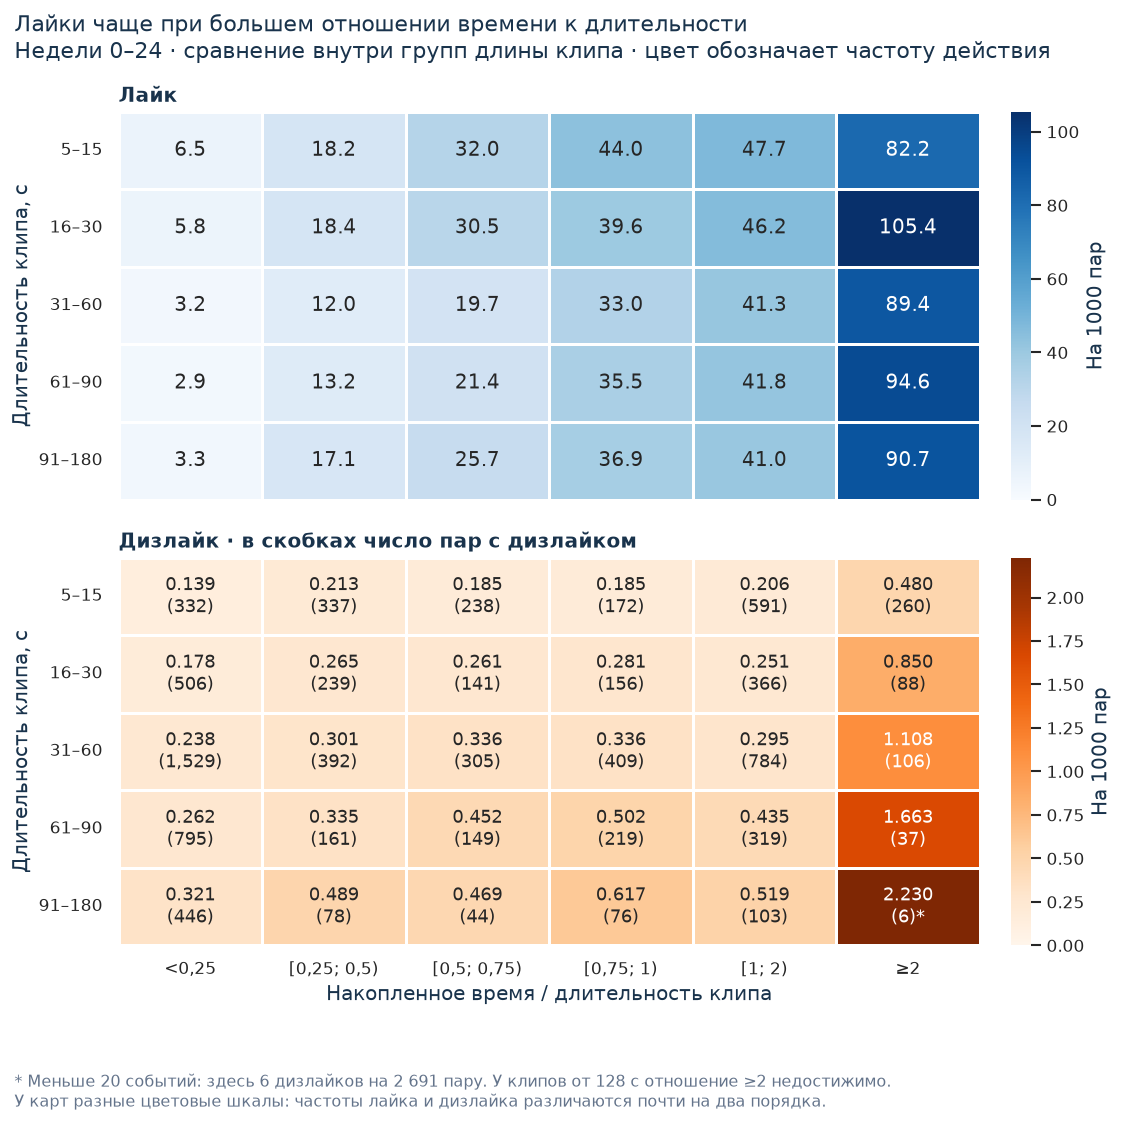

In [29]:
fig, axes =plt.subplots(2, 1, figsize=(10, 9.5), sharex=True)
sns.heatmap(ratio_likes, annot=True, fmt=".1f",
            annot_kws={"size": 12}, cmap="Blues", vmin=0,
            linewidths=0.7, linecolor="white", ax=axes[0],
            cbar_kws={"label": "На 1000 пар", "pad": 0.03})
sns.heatmap(ratio_dislike_rates, annot=dislike_annotations.to_numpy(), fmt="",
            annot_kws={"size": 11}, cmap="Oranges", vmin=0,
            linewidths=0.7, linecolor="white", ax=axes[1],
            cbar_kws={"label": "На 1000 пар", "pad": 0.03})
axes[0].set_title("Лайк")
axes[1].set_title("Дизлайк · в скобках число пар с дизлайком")
for ax in axes:
    ax.set(xlabel="", ylabel="Длительность клипа, с")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
axes[1].set_xlabel("Накопленное время / длительность клипа")
fig.text(0.02, 0.015,
         "* Меньше 20 событий: здесь 6 дизлайков на 2 691 пару. У клипов от 128 с отношение ≥2 недостижимо.\n"
         "У карт разные цветовые шкалы: частоты лайка и дизлайка различаются почти на два порядка.",
         fontsize=9.5, color=MUTED, va="bottom")
fig.suptitle('Лайки чаще при большем отношении времени к длительности\nНедели 0–24 · сравнение внутри групп длины клипа · цвет обозначает частоту действия', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

In [30]:
print("Число пар в каждой группе — знаменатели обеих карт")
display(ratio_n)

Число пар в каждой группе — знаменатели обеих карт


ratio_bin,"<0,25","[0,25; 0,5)","[0,5; 0,75)","[0,75; 1)",[1; 2),≥2
duration_bin,,,,,,
5–15,2394115,1579005,1288454,927513,2870626,542230
16–30,2837717,900993,539383,554950,1456751,103548
31–60,6432677,1301531,908669,1216206,2659551,95644
61–90,3032186,481154,329399,436310,732775,22248
91–180,1391332,159476,93837,123204,198272,2691


Между группами длительности 5–15 и 91–180 с среднее время растёт с 7,29 до 33,90 с, а частота лайка снижается с 32,06 до 11,51 на 1000 пар. Возможное предпочтение длинных клипов при ранжировании по секундам предстоит проверить на модели.

Внутри каждой из пяти групп длины частота лайка растёт с отношением времени к длительности. Для клипов 31–60 с она равна 3,21 на 1000 при отношении <0,25, 33,03 при 0,75–1 и 89,38 при ≥2. Группировка частично учитывает длину клипа; различия пользователей и контента здесь не контролировались.

Для дизлайков число событий и частота меняются в разные стороны. В клипах 31–60 с между крайними группами число событий падает с 1529 до 106, но частота растёт с 0,238 до 1,108 на 1000: объёмы групп сильно различаются.

Группа длительности 91–180 с с отношением ≥2 содержит 2691 пару и 6 дизлайков. Клипы от 128 с в неё не попадают из-за ограничения времени. Результат этой группы нельзя переносить на все длинные клипы.

### Корреляции

Pearson рассчитан по всем строкам для числовых полей и бинарных реакций. ID и номинальные коды исключены. Отношение времени к длительности вычислено из соседних полей, поэтому часть его связей с ними задана самой формулой.

In [31]:
numeric_fields = ["timespent", "duration", "watch_ratio", "age"] + REACTIONS
correlations = []
for field in numeric_fields:
    row = con.sql("""
        SELECT corr("{field}"::DOUBLE, timespent::DOUBLE) AS timespent,
               corr("{field}"::DOUBLE, duration::DOUBLE) AS duration,
               corr("{field}"::DOUBLE, watch_ratio) AS watch_ratio,
               corr("{field}"::DOUBLE, age::DOUBLE) AS age,
               corr("{field}"::DOUBLE, "like"::DOUBLE) AS "like",
               corr("{field}"::DOUBLE, dislike::DOUBLE) AS dislike,
               corr("{field}"::DOUBLE, share::DOUBLE) AS share,
               corr("{field}"::DOUBLE, bookmark::DOUBLE) AS bookmark,
               corr("{field}"::DOUBLE, click_on_author::DOUBLE) AS click_on_author,
               corr("{field}"::DOUBLE, open_comments::DOUBLE) AS open_comments
        FROM facts
    """.format(field=field)).df()
    row.index = [field]
    correlations.append(row)
correlations = pd.concat(correlations)[numeric_fields]

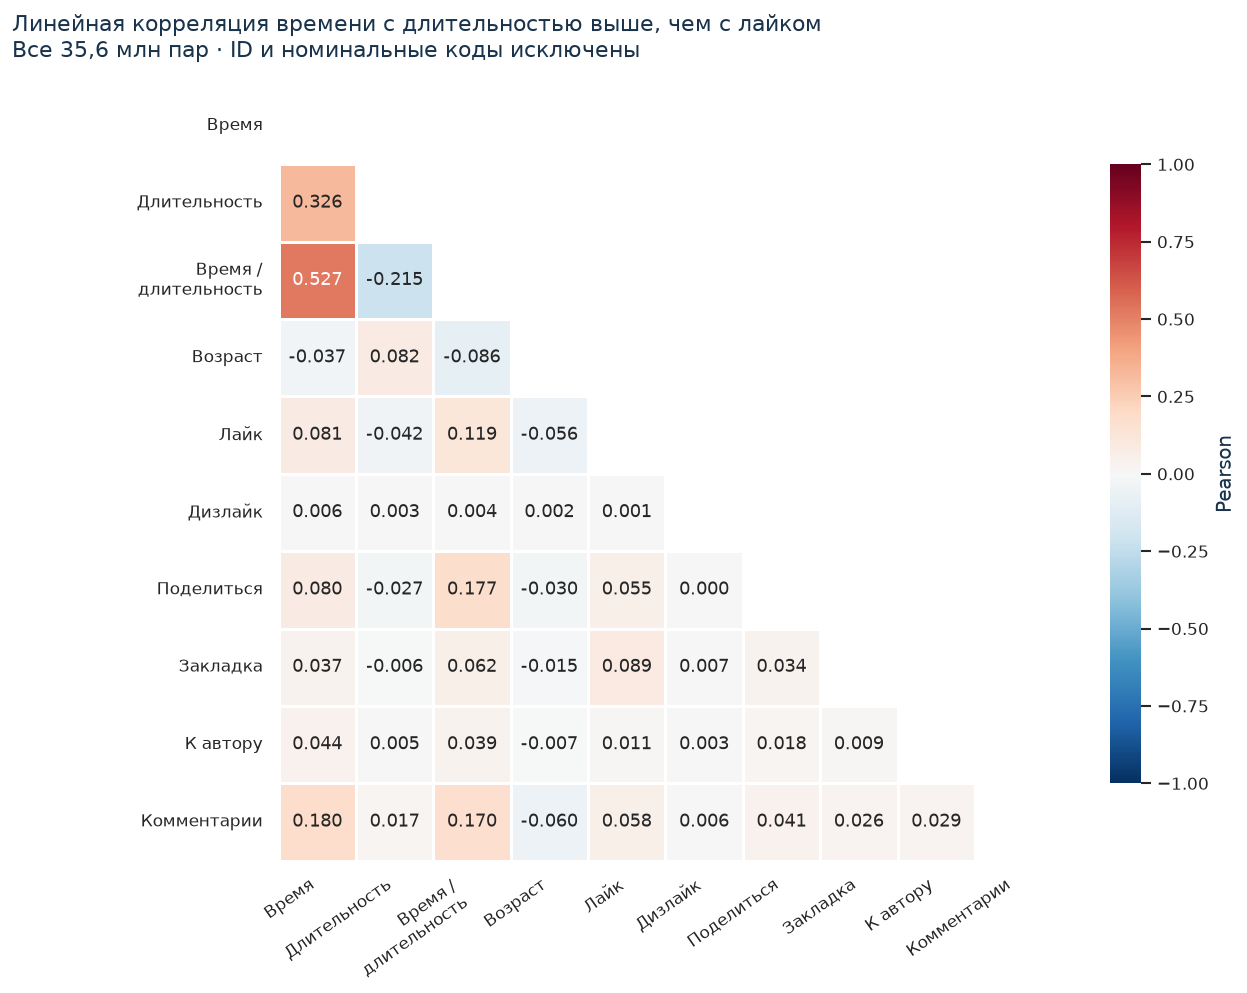

In [32]:
corr_labels = LABELS.copy()
corr_labels.update({"timespent": "Время", "duration": "Длительность",
                    "watch_ratio": "Время /\nдлительность", "age": "Возраст"})
table = correlations.rename(index=corr_labels, columns=corr_labels)
# Матрица симметрична: показываем только нижнюю половину без диагонали.
upper_triangle = np.triu(np.ones(table.shape, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8.6))
sns.heatmap(table, mask=upper_triangle, annot=True, fmt=".3f", annot_kws={"size": 10.5},
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.7, ax=ax, cbar_kws={"label": "Pearson", "shrink": 0.8})
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.suptitle('Линейная корреляция времени с длительностью выше, чем с лайком\nВсе 35,6 млн пар · ID и номинальные коды исключены', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

Коэффициент Пирсона для времени и длительности равен 0,326, для времени и лайка — 0,081, для времени и дизлайка — 0,006. У отношения времени к длительности корреляция с лайком равна 0,119, с действием «поделиться» — 0,177. Малый коэффициент для редкой бинарной реакции не исключает различий между группами, показанных выше.

Для pairplot выбраны 100 000 пар по фиксированному хешу. Преобразование log(1 + x) сжимает хвосты распределений; плотности на диагонали нормированы внутри каждой группы лайка.

Точки с лайком показаны более контрастным слоем поверх точек без лайка. Численность групп указана в легенде; по плотности цвета её сравнивать нельзя.

In [33]:
plot_sample = con.sql("""
    SELECT timespent::INTEGER AS timespent, duration::INTEGER AS duration,
           watch_ratio, "like", dislike
    FROM facts ORDER BY hash(user_id, item_id, 42) LIMIT 100000
""").df()
print(f"Выборка для pairplot: {len(plot_sample):,} строк; "
      f"лайков {int(plot_sample['like'].sum()):,}, дизлайков {int(plot_sample['dislike'].sum()):,}.")
pair_data = pd.DataFrame({
    "log(1 + t)": np.log1p(plot_sample["timespent"]),
    "Длительность d, с": plot_sample["duration"],
    "log(1 + t / d)": np.log1p(plot_sample["watch_ratio"]),
    "Лайк": np.where(plot_sample["like"], "есть", "нет")
})

Выборка для pairplot: 100,000 строк; лайков 2,057, дизлайков 31.


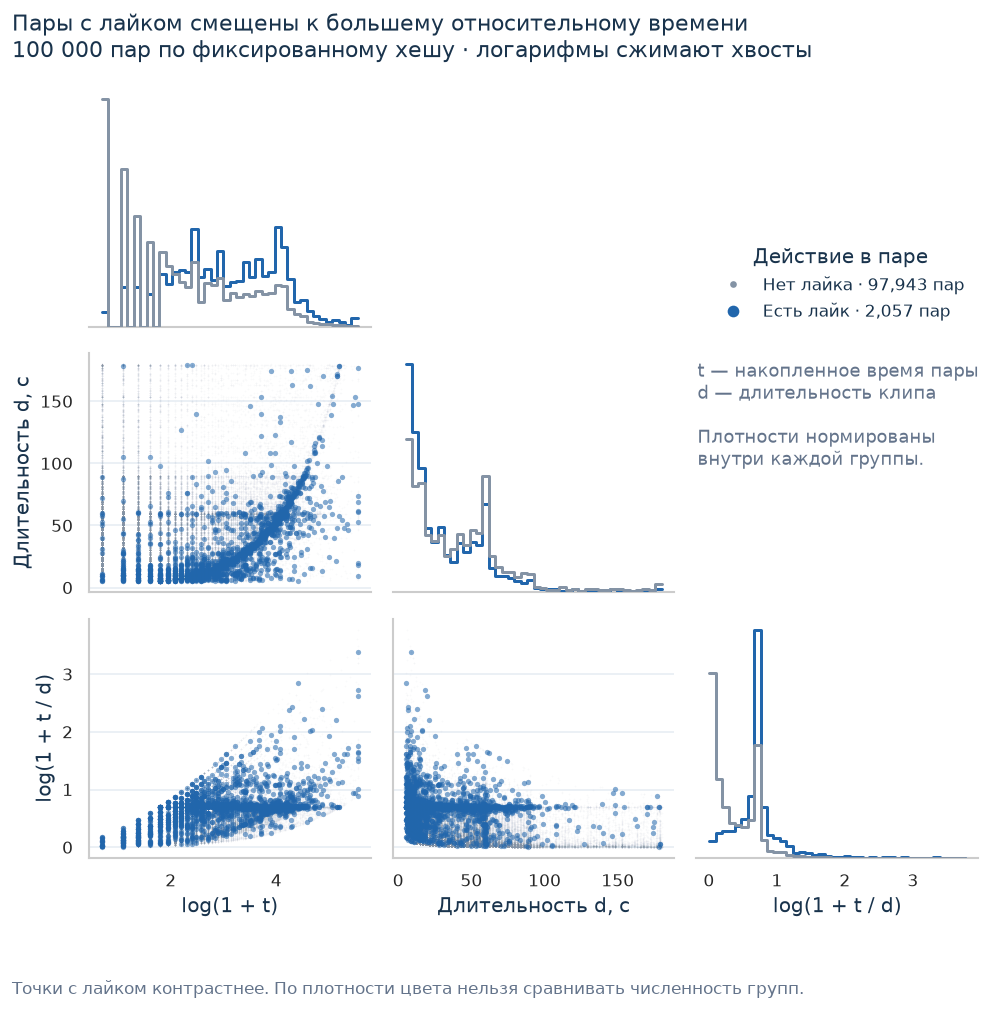

In [34]:
pair = sns.PairGrid(
    pair_data, vars=["log(1 + t)", "Длительность d, с", "log(1 + t / d)"],
    hue="Лайк", hue_order=["нет", "есть"], palette={"нет": GRAY, "есть": BLUE},
    hue_kws={"alpha": [0.045, 0.55], "s": [4, 10], "marker": [".", "o"], "zorder": [1, 2]},
    corner=True, height=2.8, diag_sharey=False
)
# Точки с лайком поверх точек без лайка
pair.map_lower(plt.scatter, linewidths=0, rasterized=True)
pair.map_diag(sns.histplot, bins=40, stat="density", common_norm=False,
              element="step", fill=False, linewidth=1.8)

like_count = int(plot_sample["like"].sum())
no_like_count = len(plot_sample) - like_count
legend = [
    Line2D([], [], color=GRAY, marker=".", ls="", label=f"Нет лайка · {no_like_count:,} пар"),
    Line2D([], [], color=BLUE, marker="o", ls="", label=f"Есть лайк · {like_count:,} пар")
]
pair.figure.legend(handles=legend, title="Действие в паре",
                   loc="upper right", bbox_to_anchor=(0.98, 0.76))
pair.figure.text(0.70, 0.53, "t — накопленное время пары\nd — длительность клипа\n\n"
                 "Плотности нормированы\nвнутри каждой группы.", fontsize=11, color=MUTED)
pair.figure.text(0.02, 0.005,
                 "Точки с лайком контрастнее. По плотности цвета нельзя сравнивать численность групп.",
                 fontsize=10, color=MUTED)
pair.figure.suptitle('Пары с лайком смещены к большему относительному времени\n100 000 пар по фиксированному хешу · логарифмы сжимают хвосты', x=0.02, ha="left", fontsize=13)
pair.figure.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 5. Пользователи и контекст

Возраст, пол и географию описываем по уникальным пользователям. Частоты реакций считаем по парам: в них более активные пользователи имеют больший вес. Анонимные коды используются без расшифровки.

In [35]:
category_counts = {}
for field, table in [("gender", "users"), ("geo", "users"),
                     ("place", "facts"), ("platform", "facts"), ("agent", "facts")]:
    category_counts[field] = con.sql("""
        SELECT "{field}" AS code, count(*) AS n
        FROM {table} GROUP BY "{field}" ORDER BY n DESC, code
    """.format(field=field, table=table)).df()

category_overview = []
for field, counts in category_counts.items():
    mode = counts.iloc[0]
    category_overview.append({
        "Поле": field, "Единица": "пользователь" if field in ["gender", "geo"] else "строка взаимодействий",
        "Категорий": len(counts), "Мода": int(mode["code"]),
        "Количество моды": int(mode["n"]), "Доля моды, %": 100 * mode["n"] / counts["n"].sum(),
        "Доля кода 0, %": 100 * counts.loc[counts["code"] == 0, "n"].sum() / counts["n"].sum()
    })

In [36]:
display(pd.DataFrame(category_overview))
age_dist = con.sql("SELECT age, count(*) AS n FROM users GROUP BY age ORDER BY age").df()

,Поле,Единица,Категорий,Мода,Количество моды,"Доля моды, %","Доля кода 0, %"
0,gender,пользователь,2,1,51571,51.571,0.000
1,geo,пользователь,80,79,16487,16.487,0.037
2,place,строка взаимодействий,24,1,24723954,69.425,26.533
3,platform,строка взаимодействий,11,0,23693149,66.531,66.531
4,agent,строка взаимодействий,26,0,23708237,66.573,66.573


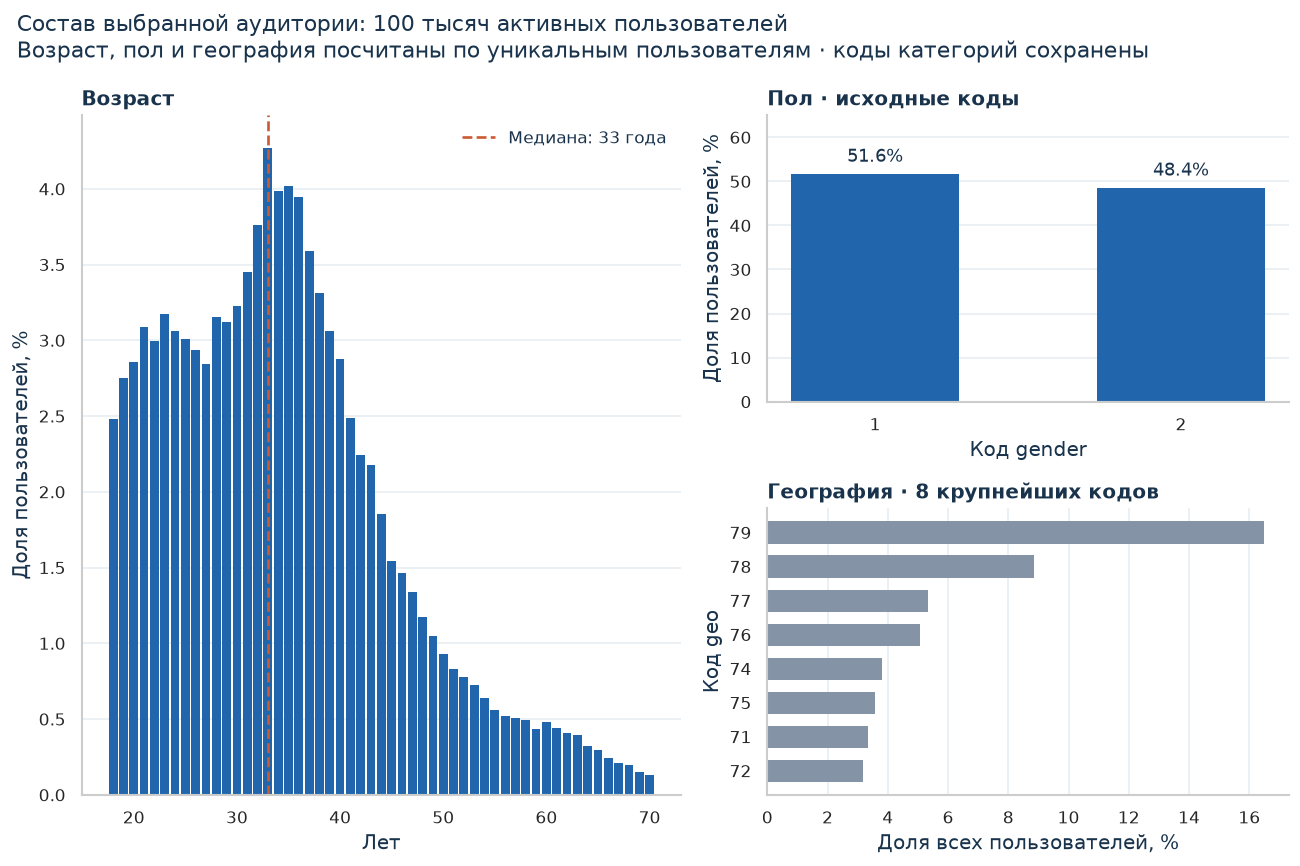

In [37]:
fig = plt.figure(figsize=(11, 7.5))
grid = fig.add_gridspec(2, 2, width_ratios=[1.15, 1])
ax_age = fig.add_subplot(grid[:, 0])
ax_gender = fig.add_subplot(grid[0, 1])
ax_geo = fig.add_subplot(grid[1, 1])
ax_age.bar(age_dist["age"], 100 * age_dist["n"] / age_dist["n"].sum(),
           width=0.85, color=BLUE, linewidth=0)
ax_age.axvline(33, color=ORANGE, ls="--", lw=1.6, label="Медиана: 33 года")
ax_age.set(title="Возраст", xlabel="Лет", ylabel="Доля пользователей, %")
ax_age.legend(loc="upper right")

genders = category_counts["gender"].sort_values("code")
gender_values = 100 * genders["n"] / genders["n"].sum()
bars = ax_gender.bar(genders["code"].astype(str), gender_values, width=0.55,
                     color=BLUE, linewidth=0)
ax_gender.bar_label(bars, fmt="%.1f%%",
                     padding=5, fontsize=11)
ax_gender.set(title="Пол · исходные коды", xlabel="Код gender",
               ylabel="Доля пользователей, %", ylim=(0, 65))

geos = category_counts["geo"].head(8).iloc[::-1]
geo_values = 100 * geos["n"] / category_counts["geo"]["n"].sum()
ax_geo.barh(geos["code"].astype(str), geo_values, color=GRAY, height=0.65, linewidth=0)
ax_geo.set(title="География · 8 крупнейших кодов", xlabel="Доля всех пользователей, %", ylabel="Код geo")
ax_geo.grid(axis="x")
ax_geo.grid(axis="y", visible=False)
fig.suptitle('Состав выбранной аудитории: 100 тысяч активных пользователей\nВозраст, пол и география посчитаны по уникальным пользователям · коды категорий сохранены', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

### Время и реакции по возрасту и полу

Знаменатель каждой частоты — число пар в соответствующей группе.

In [38]:
table = slices["age_bin"].set_index("age_bin")
table = table[profile_columns].copy()
table.columns = profile_names
table.index.name = "Возраст"
display(table)

table = slices["gender"].set_index("gender")
table = table[profile_columns].copy()
table.columns = profile_names
display(table)

,Пар,"Среднее время, с",Лайк / 1000,Дизлайк / 1000,Поделиться / 1000,Закладка / 1000,К автору / 1000,Комментарии / 1000
Возраст,,,,,,,,
18–24,7340440,18.760,43.189,0.300,7.550,2.027,2.406,29.040
25–34,12014953,17.640,17.732,0.226,5.358,0.745,2.362,15.999
35–44,10467299,16.729,13.801,0.212,2.508,0.431,1.893,8.265
45–54,3721922,15.943,15.613,0.396,2.052,0.519,1.572,6.954
55–70,2067833,16.042,14.643,0.377,1.619,0.593,1.360,6.400


,Пар,"Среднее время, с",Лайк / 1000,Дизлайк / 1000,Поделиться / 1000,Закладка / 1000,К автору / 1000,Комментарии / 1000
gender,,,,,,,,
1,18031370,17.670,18.853,0.316,4.664,0.786,1.798,11.918
2,17581077,16.987,24.059,0.210,4.148,0.986,2.394,17.981


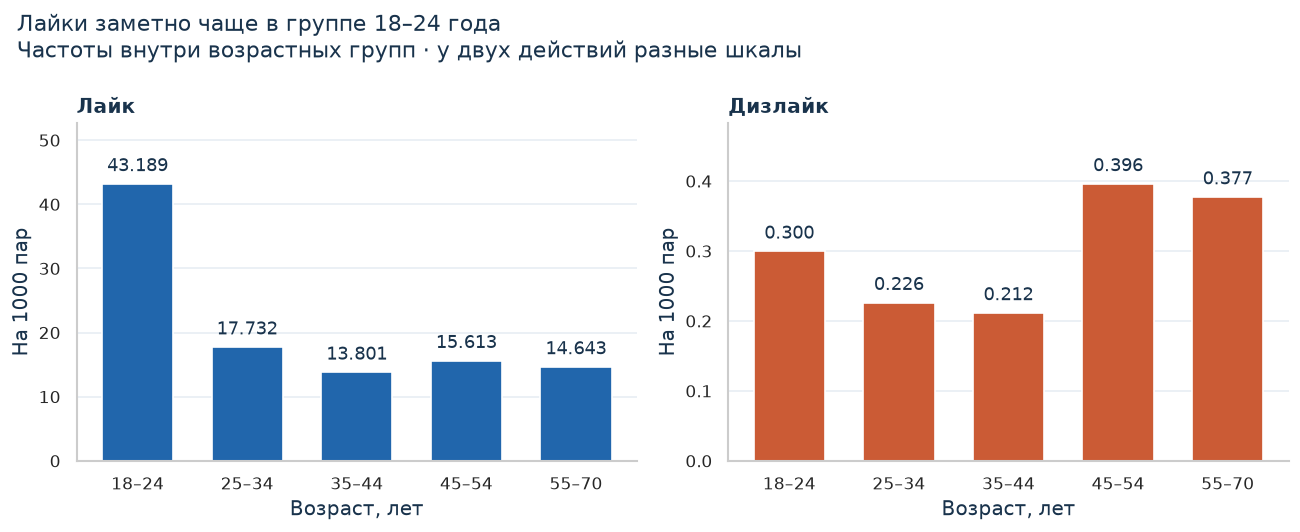

In [39]:
age_rates = slices["age_bin"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, reaction in zip(axes, ["like", "dislike"]):
    values = age_rates[f"{reaction}_per_1000"]
    bars = ax.bar(age_rates["age_bin"], values, color=COLORS[reaction], width=0.65)
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=11)
    ax.set(title=LABELS[reaction], xlabel="Возраст, лет", ylabel="На 1000 пар",
           ylim=(0, values.max() * 1.22))
fig.suptitle('Лайки заметно чаще в группе 18–24 года\nЧастоты внутри возрастных групп · у двух действий разные шкалы', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

### Контекст

На графиках показаны шесть крупнейших категорий каждого поля. Их охват приведён в первой таблице; расчёты по всем категориям доступны в `slices`.

In [40]:
context_profiles = []
coverage = []
for field in ["geo", "place", "platform", "agent"]:
    # Выбираем top-6 по объёму только для показа; все категории рассчитаны в slices.
    top = slices[field].nlargest(6, "n").copy()
    coverage.append({"Поле": field, "Показано кодов": len(top), "Доля всех пар, %": 100 * top["n"].sum() / N})
    top = top.rename(columns={field: "code"})
    top.insert(0, "field", field)
    context_profiles.append(top[["field", "code"] + profile_columns])
context_profiles = pd.concat(context_profiles, ignore_index=True)

In [41]:
display(pd.DataFrame(coverage))
table = context_profiles.copy()
table.columns = ["Поле", "Код"] + profile_names
display(table)

,Поле,Показано кодов,"Доля всех пар, %"
0,geo,6,43.023
1,place,6,99.536
2,platform,6,99.777
3,agent,6,99.978


,Поле,Код,Пар,"Среднее время, с",Лайк / 1000,Дизлайк / 1000,Поделиться / 1000,Закладка / 1000,К автору / 1000,Комментарии / 1000
0,geo,79,5878868,17.681,24.732,0.328,4.752,1.157,2.029,16.684
1,geo,78,3137869,17.160,19.335,0.300,4.731,0.903,1.987,13.788
2,geo,77,1894586,17.465,18.390,0.195,4.366,0.807,2.155,13.629
3,geo,76,1799887,16.955,19.168,0.345,4.472,0.664,2.087,13.635
4,geo,74,1351230,17.863,28.668,0.238,4.229,1.008,1.986,15.219
5,geo,75,1259068,17.892,24.065,0.268,4.217,0.840,2.234,15.799
6,place,1,24723954,18.898,25.695,0.298,4.760,1.055,1.932,19.204
7,place,0,9448881,13.988,11.827,0.166,3.316,0.347,0.930,4.016
8,place,2,667694,10.288,4.268,0.506,2.387,0.481,2.509,9.543
9,place,3,330410,14.591,17.036,0.188,3.547,2.542,45.783,22.027


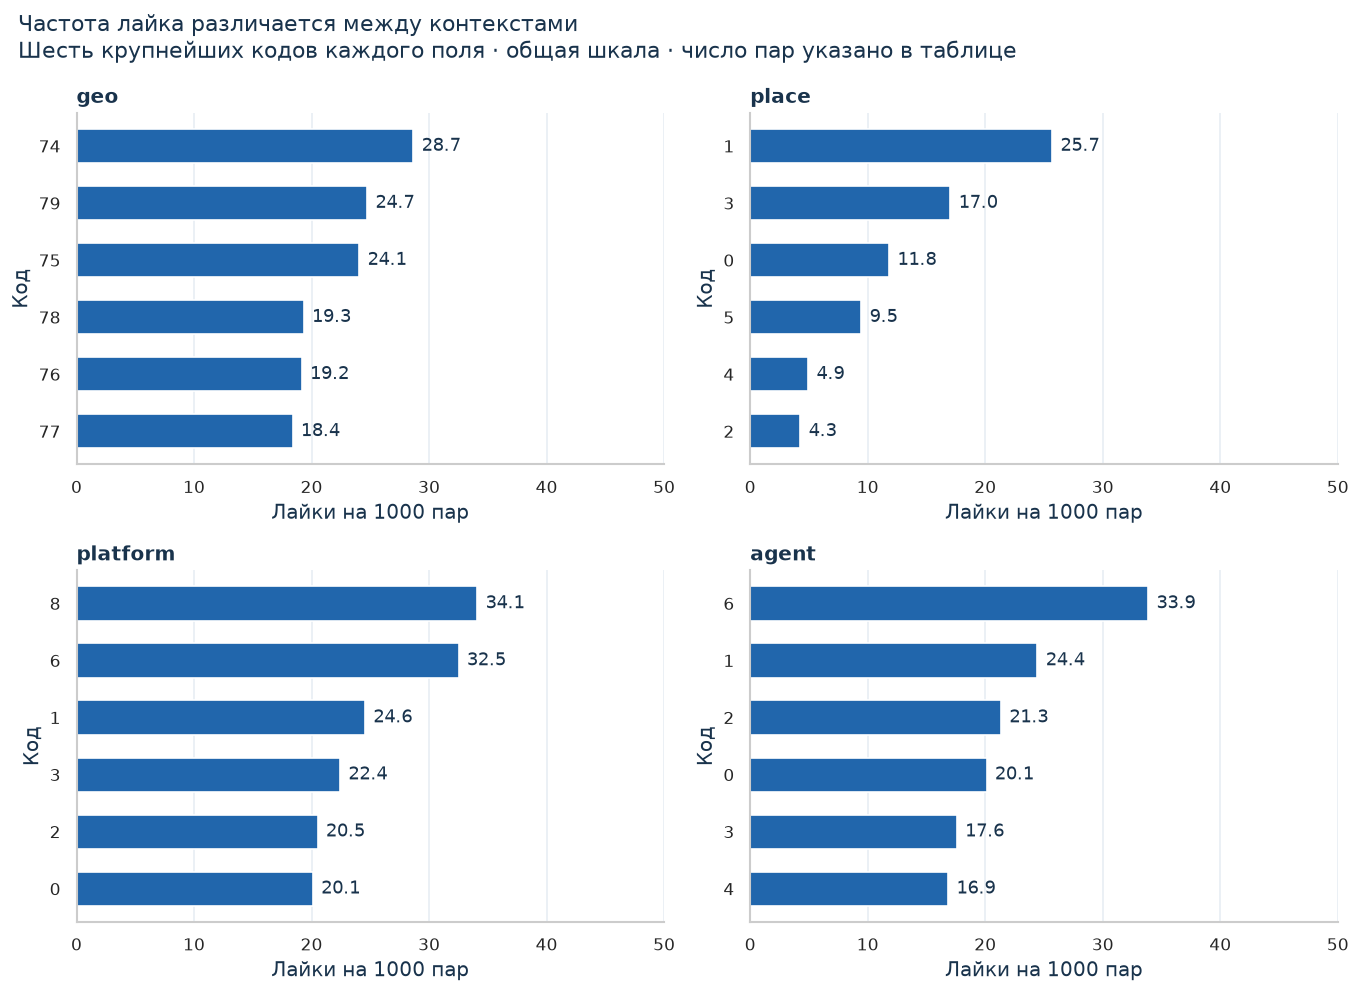

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.6), sharex=True)
for ax, field in zip(axes.flat, ["geo", "place", "platform", "agent"]):
    top = context_profiles.loc[context_profiles["field"] == field]
    top = top.sort_values("like_per_1000")
    bars = ax.barh(top["code"].astype(str), top["like_per_1000"], color=BLUE, height=0.6)
    ax.bar_label(bars, fmt="%.1f", padding=5, fontsize=11)
    ax.set(title=field, xlabel="Лайки на 1000 пар", ylabel="Код", xlim=(0, 50))
    ax.set_xticks([0, 10, 20, 30, 40, 50])
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
fig.suptitle('Частота лайка различается между контекстами\nШесть крупнейших кодов каждого поля · общая шкала · число пар указано в таблице', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

В группе 18–24 года — 43,19 лайка на 1000 пар, в группе 35–44 — 13,80. Помимо возраста, группы могут различаться показанным контентом и привычкой пользоваться реакциями.

Для place 0, 1 и 2 частоты лайка равны 11,83, 25,69 и 4,27 на 1000 пар, среднее время — 13,99, 18,90 и 10,29 с. Названия поверхностей по этим кодам неизвестны.

На platform=2 среди 1 648 248 пар есть 33 819 лайков, но только 20 действий «поделиться» и 118 открытий комментариев. Частота «поделиться» примерно в 511 раз ниже, чем на platform=1, при близких частотах лайка. Возможные причины — доступность действий, их регистрация, состав аудитории или контента. Данных для выбора причины нет.

Отсутствие NULL не гарантирует одинаковую регистрацию реакций. Нулевые флаги сохраняются; качество модели нужно сравнивать по платформам и группам пользователей. Демографию и контекст можно использовать как признаки, если они известны до рекомендации.

## 6. Активность пользователей, клипов и авторов

У пользователя считаем число разных клипов, у клипа — число разных пользователей, у автора — сумму пар по его клипам. Эти величины описывают активность внутри среза.

In [43]:
con.execute("""
    CREATE TEMP TABLE entity_activity AS
    SELECT 'Пользователь' AS entity, user_id AS entity_id, count(*) AS n FROM facts GROUP BY user_id
    UNION ALL
    SELECT 'Клип', item_id, count(*) FROM facts GROUP BY item_id
    UNION ALL
    SELECT 'Автор', author_id, count(*) FROM facts GROUP BY author_id
""");

In [44]:
# Сортируем сущности по активности: первые 1% дают долю наиболее популярных.
activity_stats = con.sql("""
    WITH ranked AS (
        SELECT *, row_number() OVER (PARTITION BY entity ORDER BY n DESC, entity_id) AS position,
               count(*) OVER (PARTITION BY entity) AS total_entities
        FROM entity_activity
    )
    SELECT entity, count(*) AS entities_cnt, sum(n) AS rows_cnt,
           min(n) AS min_n, avg(n) AS mean_n, median(n) AS median_n,
           quantile_cont(n, 0.90) AS p90, quantile_cont(n, 0.99) AS p99,
           quantile_cont(n, 0.999) AS p999, max(n) AS max_n,
           100.0 * sum(n) FILTER (WHERE position <= ceil(0.01 * total_entities)) / sum(n) AS top_1pct_share
    FROM ranked GROUP BY entity ORDER BY entity
""").df()
assert activity_stats["rows_cnt"].eq(N).all()

In [45]:
table = activity_stats.copy()
table.columns = ["Сущность", "Количество", "Всего пар", "Минимум", "Среднее", "Медиана",
                 "P90", "P99", "P99.9", "Максимум", "Доля пар у top-1%, %"]
display(table)

activity_hist = con.sql("""
    SELECT entity, n, count(*) AS entities_cnt
    FROM entity_activity GROUP BY entity, n ORDER BY entity, n
""").df()

,Сущность,Количество,Всего пар,Минимум,Среднее,Медиана,P90,P99,P99.9,Максимум,"Доля пар у top-1%, %"
0,Автор,68237,"35,612,447.000",1,521.894,8.000,587.400,"11,034.920","40,688.496",214775,47.303
1,Клип,165821,"35,612,447.000",1,214.764,13.000,338.000,"3,831.800","14,703.900",84621,38.478
2,Пользователь,100000,"35,612,447.000",219,356.124,337.000,461.000,582.000,656.000,727,1.726


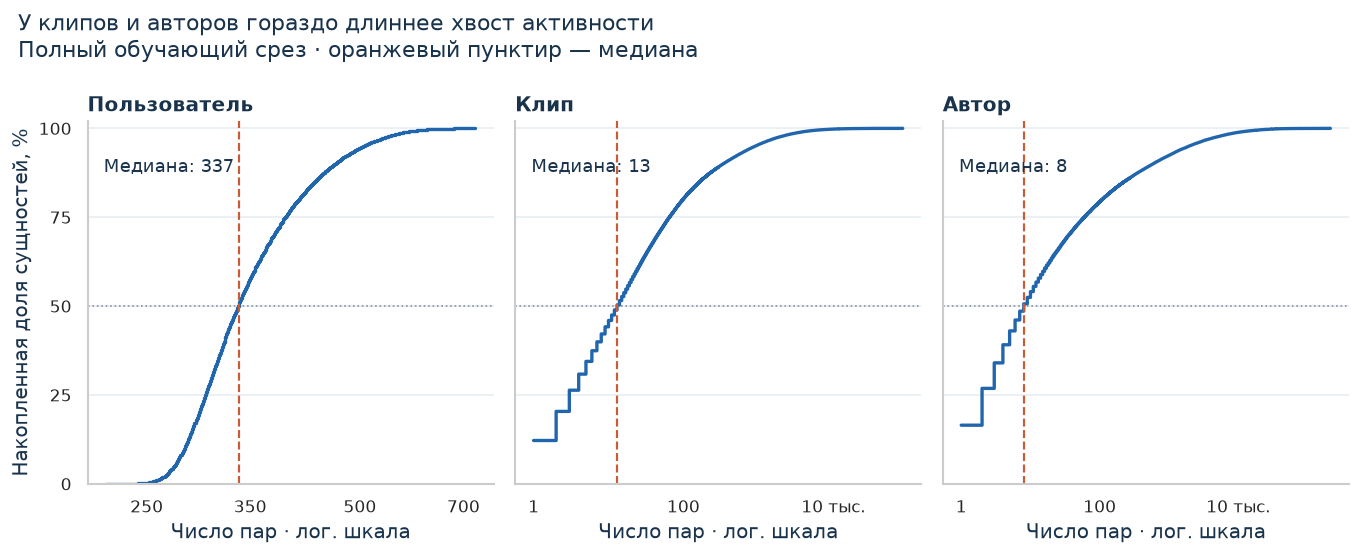

In [46]:
medians = activity_stats.set_index("entity")["median_n"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.8), sharey=True)
for ax, entity in zip(axes, ["Пользователь", "Клип", "Автор"]):
    part = activity_hist.loc[activity_hist["entity"] == entity]
    cumulative_pct = 100 * part["entities_cnt"].cumsum() / part["entities_cnt"].sum()
    median_value = medians.loc[entity]
    ax.step(part["n"], cumulative_pct, where="post", color=BLUE, lw=2)
    ax.axhline(50, color=GRAY, ls=":", lw=1)
    ax.axvline(median_value, color=ORANGE, ls="--", lw=1.3)
    ax.text(0.04, 0.86, f"Медиана: {median_value:.0f}", transform=ax.transAxes, fontsize=11)
    ax.set(title=entity, xlabel="Число пар · лог. шкала", xscale="log", ylim=(0, 102))
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.minorticks_off()

axes[0].set_xticks([250, 350, 500, 700], labels=["250", "350", "500", "700"])
axes[1].set_xticks([1, 100, 10000], labels=["1", "100", "10 тыс."])
axes[2].set_xticks([1, 100, 10000], labels=["1", "100", "10 тыс."])
axes[0].set_ylabel("Накопленная доля сущностей, %")
fig.suptitle('У клипов и авторов гораздо длиннее хвост активности\nПолный обучающий срез · оранжевый пунктир — медиана', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

### Проверка крайних значений

Правило 1,5 межквартильного размаха отмечает наблюдения ниже Q25 − 1,5 × (Q75 − Q25) или выше Q75 + 1,5 × (Q75 − Q25). Попадание за эти границы само по себе не означает ошибку.

In [47]:
outlier_checks = []
for row_index, field, table in [(0, "timespent", "facts"), (1, "duration", "items"), (2, "age", "users")]:
    q1, q3 = numeric_stats.loc[row_index, ["p25", "p75"]]
    lower, upper = float(q1 - 1.5 * (q3 - q1)), float(q3 + 1.5 * (q3 - q1))
    part = con.sql("""
        SELECT count(*) AS n,
               count(*) FILTER (WHERE "{field}" < {lower} OR "{field}" > {upper}) AS outside_iqr
        FROM {table}
    """.format(field=field, table=table, lower=lower, upper=upper)).df()
    outlier_checks.append({
        "Поле": field, "Единица": numeric_stats.loc[row_index, "unit"],
        "Нижняя граница": lower, "Верхняя граница": upper,
        "За границами": int(part.loc[0, "outside_iqr"]),
        "Доля, %": 100 * part.loc[0, "outside_iqr"] / part.loc[0, "n"]
    })
display(pd.DataFrame(outlier_checks))

,Поле,Единица,Нижняя граница,Верхняя граница,За границами,"Доля, %"
0,timespent,строки взаимодействий,-28.000,52.000,3378053,9.486
1,duration,уникальные клипы,-48.000,112.000,4675,2.819
2,age,уникальные пользователи,3.500,63.500,1545,1.545


У пользователя медиана — 337 пар, диапазон — 219–727. У клипа медиана — 13 пользователей, максимум — 84 621. Верхний 1% клипов собирает 38,48% всех пар. Среди 68 237 авторов на верхний 1% приходится 47,30% пар.

Правило 1,5 IQR отмечает 9,49% строк по времени (>52 с), 2,82% клипов по длительности (>112 с) и 1,55% пользователей по возрасту (>63,5 года). Эти значения сами по себе допустимы, поэтому строки сохраняются. Для моделей можно проверить преобразование времени, устойчивую функцию потерь и регуляризацию.

Качество модели нужно считать как по всем парам, так и с равным весом пользователей. Агрегаты активности для признаков должны использовать только историю до предсказания.

## 7. Недельная динамика

Строка относится к неделе первого взаимодействия пары. Графики показывают объём таких пар и их записанные исходы; это не календарная статистика всех повторных просмотров.

In [48]:
weekly = slices["week"].set_index("week")
columns = ["n", "time_mean", "duration_mean"] + rate_columns
table = weekly[columns].copy()
table.columns = ["Пар", "Среднее время, с", "Средняя длительность, с"] + profile_names[2:]
display(table)

,Пар,"Среднее время, с","Средняя длительность, с",Лайк / 1000,Дизлайк / 1000,Поделиться / 1000,Закладка / 1000,К автору / 1000,Комментарии / 1000
week,,,,,,,,,
0,765158,17.465,40.545,25.593,0.254,5.306,1.179,2.047,13.470
1,1140448,17.456,40.272,22.606,0.195,3.977,0.885,1.744,12.029
2,1245923,16.964,39.739,22.110,0.244,4.596,0.862,2.316,13.832
3,1238891,15.306,37.385,21.312,0.211,4.039,0.789,2.013,12.997
4,1363033,15.745,36.175,22.881,0.231,4.468,0.828,2.026,13.501
5,921073,15.921,36.930,25.054,0.305,6.206,1.069,2.215,16.588
6,1178675,16.657,37.504,22.661,0.257,5.598,0.915,2.146,15.981
7,1526896,16.213,37.739,20.566,0.246,5.175,0.868,1.933,13.922
8,1629895,15.901,38.187,21.117,0.255,5.341,0.853,1.917,13.733


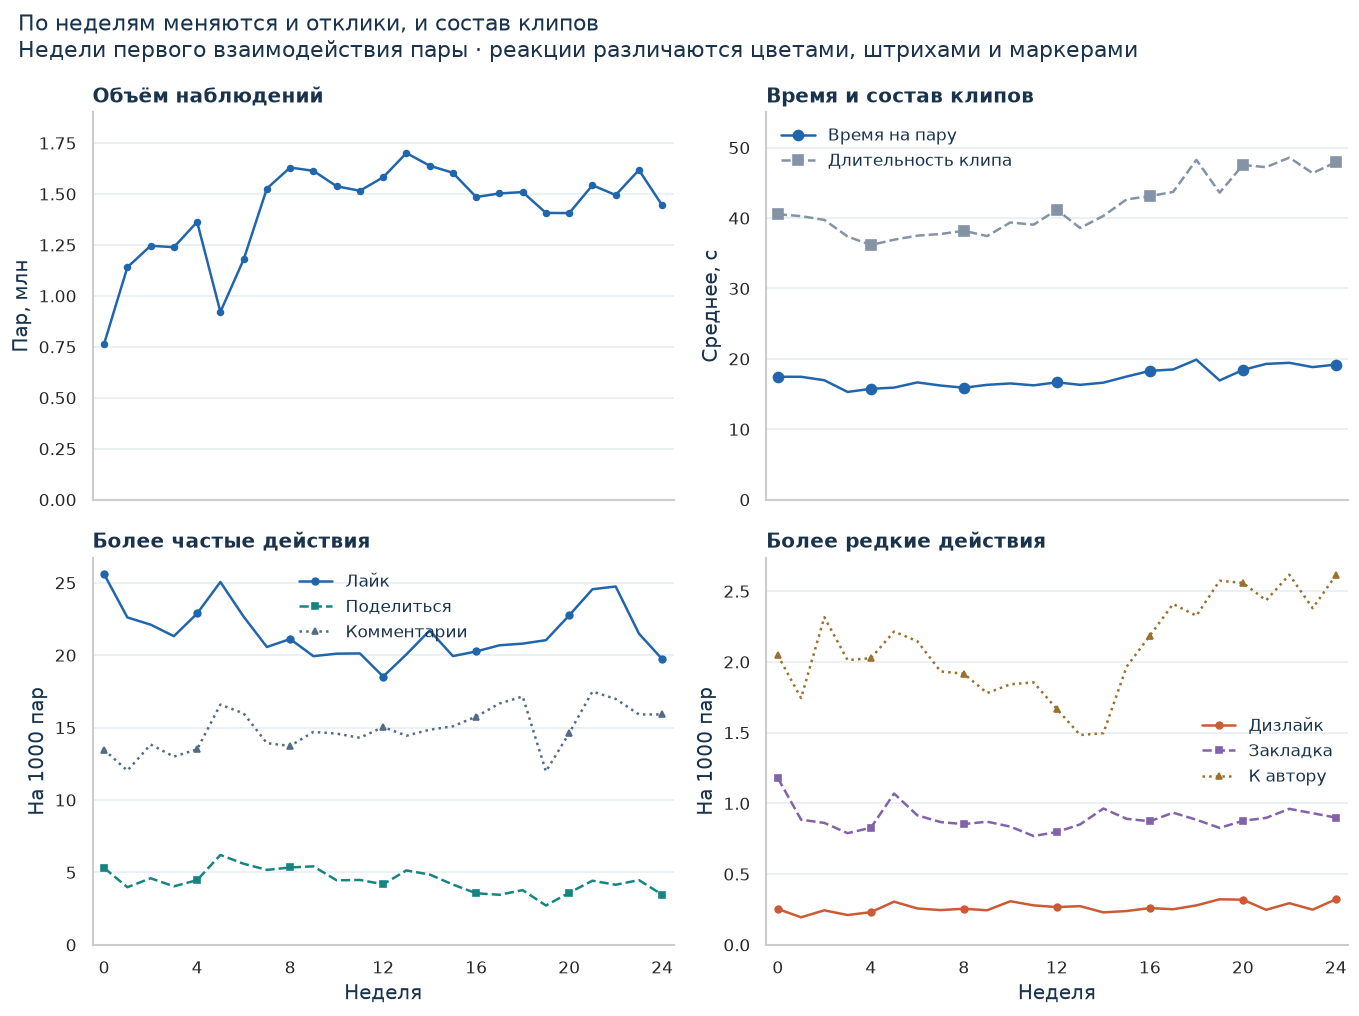

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.8), sharex=True)
axes[0, 0].plot(weekly.index, weekly["n"] / 1e6, marker="o", ms=3.5, color=BLUE)
axes[0, 0].set(title="Объём наблюдений", ylabel="Пар, млн", ylim=(0, 1.9))
axes[0, 1].plot(weekly.index, weekly["time_mean"], label="Время на пару", color=BLUE,
                marker="o", markevery=4)
axes[0, 1].plot(weekly.index, weekly["duration_mean"], label="Длительность клипа", color=GRAY,
                ls="--", marker="s", markevery=4)
axes[0, 1].set(title="Время и состав клипов", ylabel="Среднее, с", ylim=(0, 55))
axes[0, 1].legend()

# Явно задаём панель, действие и стиль каждой линии.
lines = [
    (axes[1, 0], "like", "-", "o"), (axes[1, 0], "share", "--", "s"),
    (axes[1, 0], "open_comments", ":", "^"), (axes[1, 1], "dislike", "-", "o"),
    (axes[1, 1], "bookmark", "--", "s"), (axes[1, 1], "click_on_author", ":", "^")
]
for ax, reaction, linestyle, marker in lines:
    ax.plot(weekly.index, weekly[f"{reaction}_per_1000"], label=LABELS[reaction],
            color=COLORS[reaction], ls=linestyle, marker=marker, markevery=4, ms=4)
axes[1, 0].set_title("Более частые действия")
axes[1, 1].set_title("Более редкие действия")
for ax in axes[1]:
    ax.set(ylabel="На 1000 пар", xlabel="Неделя", ylim=(0, None))
    ax.legend()
for ax in axes.flat:
    ax.set_xticks(range(0, 25, 4))
    ax.set_xlim(-0.5, 24.5)
fig.suptitle('По неделям меняются и отклики, и состав клипов\nНедели первого взаимодействия пары · реакции различаются цветами, штрихами и маркерами', x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

С недели 0 по неделю 24 среднее время выросло с 17,47 до 19,19 с, средняя длительность клипа в строке — с 40,54 до 47,94 с. Частота лайка снизилась с 25,59 до 19,73 на 1000 пар. Внутри периода показатели колеблются; изменение состава пользователей, клипов и контекстов здесь не отделено от других причин.

План разделения данных: недели 0–24 — обучение, 25 — валидация, 26 — тест. При предварительном знакомстве с датасетом была просмотрена общая сводка недель 25–26; в расчёты этого ноутбука эти файлы не входят. Перед обучением нужно уточнить границы накопления исходов пары: неделя первого взаимодействия сама по себе их не задаёт.

## 8. Подготовка данных

| Что обнаружено | Решение |
|---|---|
| Нет NULL, дубликатов пар и потерь при соединении | Заполнение и удаление дублей не нужны |
| Смысл нулевых кодов не документирован | Сохранить отдельными категориями |
| Время накоплено по паре и ограничено 255 с | Предсказывать записанное время; отношение к длительности не считать фактическим досмотром |
| Есть длинные хвосты времени, длительности и активности | Сохранить наблюдения; проверить преобразования и регуляризацию при моделировании |
| Реакции редки и пересекаются | Использовать отдельные бинарные цели; не оценивать модель только по accuracy |
| У 306 пар есть и лайк, и дизлайк | Сохранить оба флага: порядок действий неизвестен |
| Текущее время и реакции известны после показа | Исключить их из признаков ранкера, который предсказывает эти исходы |
| Ранги и агрегаты рассчитаны по всему периоду | Не использовать их как готовые исторические признаки; пересчитывать с временной отсечкой |

ID подходят для представлений пользователей, клипов и авторов. Числовое расстояние между ID содержательного смысла не имеет.

## 9. Выводы

- У пар с лайком среднее время выше, но в 45,08% таких пар оно меньше длительности клипа. Большое время встречается и при дизлайке, поэтому время не заменяет явную оценку
- У длинных клипов выше среднее время и ниже частота лайка. Внутри пяти групп длительности частота лайка растёт с отношением времени к длине клипа
- В 95,92% пар нет явных реакций; дизлайк есть в 0,0264%. Качество прогноза каждой реакции нужно оценивать отдельно с учётом её редкости
- Результаты относятся к наиболее активным пользователям и уже показанным клипам. Частоты различаются по возрасту и контексту, а небольшая доля клипов собирает большую часть взаимодействий

Сначала построим прогноз времени по историческому среднему клипа, затем обучим CatBoost на время. После этого добавим модель лайка и сравним порядок клипов по времени и по сочетанию двух прогнозов.

Лайк выбран как наиболее частая явная положительная реакция. Действия «поделиться» и «закладка» можно добавить позже, дизлайк — отслеживать как отрицательный исход. Открытие комментариев и переход к автору не обязательно означают положительную оценку клипа.

Модели сравниваются на одной выборке, с одинаковым временным разделением и набором кандидатов. Для времени считаются MAE и RMSE, для порядка клипов — NDCG@K по записанному времени и лайкам. Веса сочетания прогнозов подбираются на валидации с показом обеих метрик: прироста по лайкам и изменения по времени. Результаты также сравниваются по пользователям, длительности клипов и платформам.

Офлайн-проверка оценивает порядок уже наблюдавшихся пар. Влияние на реальные рекомендации требует отдельного эксперимента.

In [50]:
# Проверки целостности рассчитанных таблиц.
assert int(passport.loc[0, "users_cnt"]) == 100_000
assert int(passport.loc[0, "items_cnt"]) == 165_821
assert time_dist["n"].sum() == N
assert duration_dist["n"].sum() == passport.loc[0, "items_cnt"]
assert np.array_equal(np.diag(cooccurrence), reaction_summary["reaction_cnt"])
assert np.allclose(correlations, correlations.T)
assert np.allclose(np.diag(correlations), 1)
assert ratio_n.to_numpy().sum() == N
assert list(weekly.index) == list(range(25))

count_columns = ["like_cnt", "dislike_cnt", "share_cnt", "bookmark_cnt",
                 "click_on_author_cnt", "open_comments_cnt"]
for part in slices.values():
    assert part["n"].sum() == N
    totals = part[count_columns].sum().to_numpy()
    assert np.array_equal(totals, reaction_summary["reaction_cnt"])

con.close()
print("Проверки пройдены: 35 612 447 пар, недели 0–24.")

Проверки пройдены: 35 612 447 пар, недели 0–24.
